# Этап 4. Базовые модели: наивные, скользящее среднее, Holt-Winters, SARIMA

#### Holdout: последние 28 дней скрыты от моделей. Метрики: MAE, RMSE, WAPE.

In [1]:
# Импорты
import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.helpers import save_fig, save_table

warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
# данные + ряд CA_3
DATA = ROOT / "data" / "raw"
sales = pd.read_csv(DATA / "sales_train_validation.csv")
calendar = pd.read_csv(DATA / "calendar.csv")
day_cols = [c for c in sales.columns if c.startswith("d_")]

ca_3 = sales.loc[sales["store_id"] == "CA_3", day_cols].sum()
s = pd.Series(ca_3.values,
             index=pd.to_datetime(calendar["date"].iloc[:len(day_cols)]),
             name="sales").astype("float64")
print(f"{s.index.min().date()} -> {s.index.max().date()} | дней: {len(s)}")

2011-01-29 -> 2016-04-24 | дней: 1913


In [3]:
# holdout
H = 28   # горизонт прогноза, как в M5
train, test = s.iloc[:-H], s.iloc[-H:]
print(f"train: {train.index.min().date()} .. {train.index.max().date()} ({len(train)} дн)")
print(f"test:  {test.index.min().date()} .. {test.index.max().date()} ({len(test)} дн)")

train: 2011-01-29 .. 2016-03-27 (1885 дн)
test:  2016-03-28 .. 2016-04-24 (28 дн)


In [4]:
# бейзлайны
def metrics_row(y_fact, y_pred, name):
    """MAE / RMSE / WAPE для одного прогноза."""
    err = y_fact - y_pred
    return {
        "модель": name,
        "MAE": round(np.mean(np.abs(err)), 1),
        "RMSE": round(np.sqrt(np.mean(err**2)), 1),
        "WAPE, %": round(100 * np.abs(err).sum() / np.abs(y_fact).sum(), 1)
    }

results = []

# 1) наивный «последний уровень»: вчерашний день копируем на весь горизонт
naive_last = pd.Series(train.iloc[-1], index=test.index)
results.append(metrics_row(test, naive_last, "наивный: последний уровень"))

# 2) сезонный наивный, лаг 7: прошлую неделю повторяем 4 раза
naive_7 = pd.Series(np.tile(train.iloc[-7:].values, H // 7), index=test.index)
results.append(metrics_row(test, naive_7, "сезонный наивный (лаг 7)"))

# 3) сезонный наивный, лаг 28: тот же день недели 4 недели назад
naive_28 = pd.Series(train.iloc[-H:].values, index=test.index)
results.append(metrics_row(test, naive_28, "сезонный навиный (лаг 28)"))

# 4) скользящее среднее: среднее последних 28 дней train, константой на горизонт
ma_fc = pd.Series(train.iloc[-H:].mean(), index=test.index)
results.append(metrics_row(test, ma_fc, "скользящее среднее (окно 28)"))

pd.DataFrame(results)

,модель,MAE,RMSE,"WAPE, %"
0,наивный: последний уровень,1509.9,1696.6,23.9
1,сезонный наивный (лаг 7),411.6,515.4,6.5
2,сезонный навиный (лаг 28),379.0,471.0,6.0
3,скользящее среднее (окно 28),929.6,1063.6,14.7


In [5]:
# Holt-Winters
hw = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=7,
    initialization_method="estimated"
).fit()
hw_fc = pd.Series(hw.forecast(H).values, index=test.index)
results.append(metrics_row(test, hw_fc, "Holt-Winters (add + add, s=7)"))
print("alpha/beta/gamma:", np.round(list(hw.params.values())[:3], 3))

alpha/beta/gamma: [0.327 0.    0.032]


## SARIMA: параметры читаем с графиков

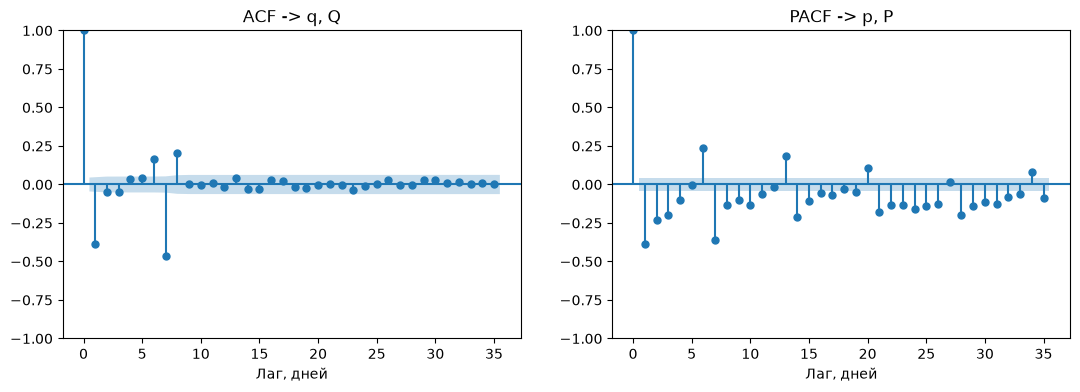

In [6]:
# ACF/PACF дифференцированного train
diffed = train.diff().diff(7).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(diffed, lags=35, ax=axes[0])
plot_pacf(diffed, lags=35, ax=axes[1], method="ywm")
axes[0].set_xlabel("Лаг, дней")
axes[1].set_xlabel("Лаг, дней")
axes[0].set_title("ACF -> q, Q")
axes[1].set_title("PACF -> p, P")
save_fig(fig, "04_models_acf_pacf_diff")

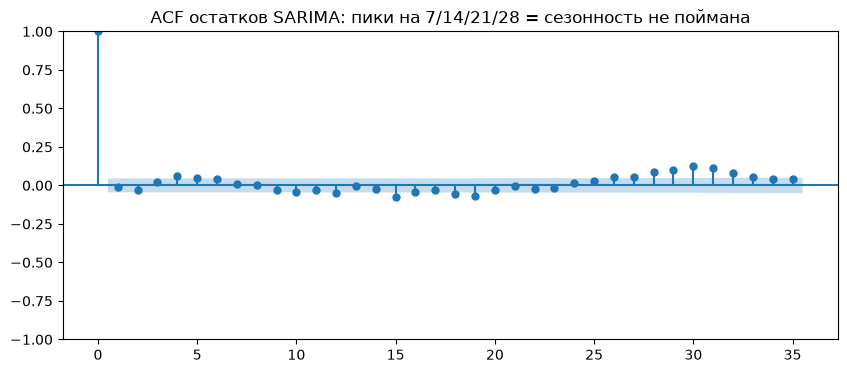

In [7]:
# SARIMA
sarima = sm.tsa.SARIMAX(
    train, order=(2, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

sarima_fc = pd.Series(sarima.forecast(H).values, index=test.index)
results.append(metrics_row(test, sarima_fc, "SARIMA (2, 1, 1)x(1, 1, 1)7"))

# диагностика: ACF остатков должна быть белым шумом
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(sarima.resid.iloc[7:], lags=35, ax=ax)
ax.set_title("ACF остатков SARIMA: пики на 7/14/21/28 = сезонность не поймана")
save_fig(fig, "04_models_sarima_residual_acf")

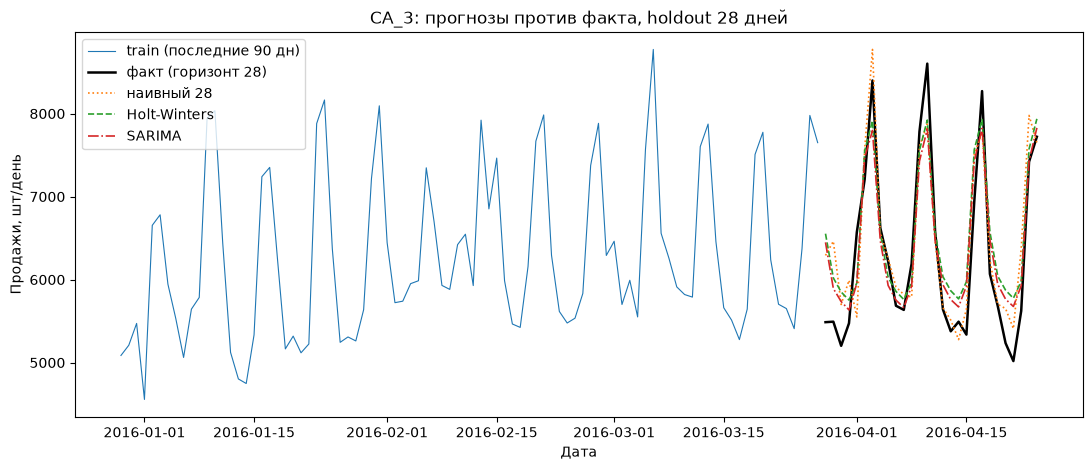

,модель,MAE,RMSE,"WAPE, %"
0,наивный: последний уровень,1509.9,1696.6,23.9
1,сезонный наивный (лаг 7),411.6,515.4,6.5
2,сезонный навиный (лаг 28),379.0,471.0,6.0
3,скользящее среднее (окно 28),929.6,1063.6,14.7
4,"Holt-Winters (add + add, s=7)",407.4,472.1,6.4
5,"SARIMA (2, 1, 1)x(1, 1, 1)7",366.4,433.2,5.8


In [8]:
# сравнение
res_df = pd.DataFrame(results)
save_table(res_df, "04_models_results_ca_3")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train.iloc[-90:], lw=0.8, label="train (последние 90 дн)")
ax.plot(test, color="black", lw=1.8, label="факт (горизонт 28)")
ax.plot(naive_28, ":", lw=1.2, label="наивный 28")
ax.plot(hw_fc, "--", lw=1.2, label="Holt-Winters")
ax.plot(sarima_fc, "-.", lw=1.2, label="SARIMA")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажи, шт/день")
ax.set_title("CA_3: прогнозы против факта, holdout 28 дней")
ax.legend()
save_fig(fig, "04_models_forecasts_vs_fact")

res_df

## Упражнение: WI_2 + проверка гипотезы (d, D) = (1, 0)

In [9]:
# WI_2, конвейер
wi2 = sales.loc[sales["store_id"] == "WI_2", day_cols].sum()
s2 = pd.Series(wi2.values, index=s.index, name="sales_wi2").astype("float64")
train2, test2 = s2.iloc[:-H], s2.iloc[-H:]

results2 = []
results2.append(metrics_row(test2, pd.Series(train2.iloc[-H:].values, index=test2.index),
                            "сезонный наивный (лаг 28)"))

hw2 = ExponentialSmoothing(train2, trend="add", seasonal="add", seasonal_periods=7,
                           initialization_method="estimated").fit()
results2.append(metrics_row(test2, pd.Series(hw2.forecast(H).values, index=test2.index),
                            "Holt-Winters (add + add, s=7)"))

sarima2 = sm.tsa.SARIMAX(train2, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7),
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
results2.append(metrics_row(test2, pd.Series(sarima2.forecast(H).values, index=test2.index),
                            "SARIMA (1,1,1)x(1,1,1)7"))

wi2_df = pd.DataFrame(results2)
save_table(wi2_df, "04_ex_wi2_results")
wi2_df

,модель,MAE,RMSE,"WAPE, %"
0,сезонный наивный (лаг 28),578.8,841.8,10.7
1,"Holt-Winters (add + add, s=7)",1089.7,1367.4,20.2
2,"SARIMA (1,1,1)x(1,1,1)7",1110.4,1382.3,20.6


In [10]:
# D=0 против D=1
specs = {
    "D=0: (1,1,1)x(1,0,1)7": ((1, 1, 1), (1, 0, 1, 7)),
    "D=1: (1,1,1)x(1,1,1)7": ((1, 1, 1), (1, 1, 1, 7)),
}
rows_d = []
for name, (order, sorder) in specs.items():
    fit_d = sm.tsa.SARIMAX(train2, order=order, seasonal_order=sorder,
                           enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc_d = pd.Series(fit_d.forecast(H).values, index=test2.index)
    err_d = test2 - fc_d
    rows_d.append({"спецификация": name,
                   "WAPE, %": round(100 * np.abs(err_d).sum() / np.abs(test2).sum(), 1)})

d_df = pd.DataFrame(rows_d)
save_table(d_df, "04_ex_wi2_D0_vs_D1")
d_df

,спецификация,"WAPE, %"
0,"D=0: (1,1,1)x(1,0,1)7",13.9
1,"D=1: (1,1,1)x(1,1,1)7",20.6


a) Рейтинг моделей WI_2 по WAPE:
  - 1-е место — сезонный наивный (лаг 28): 10.7
  - 2-е место — Holt-Winters (add + add, s=7): 20.2
  - 3-е место — SARIMA (1,1,1)x(1,1,1)7: 20.6

b) Спор D=0 vs D=1 - выиграла D=0: (1,1,1)x(1,0,1)7, WAPE 13.9 против 20.6 Моя гипотеза (d, D) = (1, 0) из этапа 3: подтвердилась. 

c) Почему сезонный наивный 28 — сильный бейзлайн в рознице: потому что недельный цикл покупок (выходные vs будни) повторяется из недели в неделю с почти неизменной амплитудой, и простое копирование значений четырёхнедельной давности точнее улавливает эту стабильную структуру, чем сложные модели, которые тратят ёмкость на подгонку шума.